# Palangka Raya, Sebangau and Kundangan AOIs, Sentinel-1 composites and surface water

Plots the AOIs on a basemap, the Sentinel-1 RTC composites (Earthdata, 30 m) made by `job/composite` as RGB (R = VV, G = VH, B = (VV - VH) / (VV + VH)), the OPERA DSWx-S1 surface water, and the Sentinel-1 composites with water masked out.

In [ ]:
import os

os.chdir(os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebook" else os.getcwd())

import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from dotenv import load_dotenv
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# override=True so the .env credentials win over anything already in the environment
load_dotenv(override=True)

# Lower resolution figures, keeps the notebook small (S1 speckle barely compresses as PNG)
plt.rcParams["figure.dpi"] = 60

AOI_PATHS = {
    "palangka_raya": "input/palangka_raya.geojson",
    "sebangau": "input/sebangau.geojson",
    "kundangan": "input/kundangan.geojson",
}
S1_PREFIX = "gs://gee-ramiqcom-s4g-bucket/forest_fire_indonesian_2026/s1"
WATER_PREFIX = "gs://gee-ramiqcom-s4g-bucket/forest_fire_indonesian_2026/surface_water_s1"
S1_DATES = ["2026-06", "2026-10"]

## Map helpers

In [ ]:
def add_lonlat(ax):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"))
    ax.tick_params(labelsize=8)
    ax.grid(color="white", linewidth=0.4, alpha=0.6, linestyle="--")


def add_north_arrow(ax, x=0.94, y=0.92):
    ax.annotate(
        "N",
        xy=(x, y),
        xytext=(x, y - 0.1),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        arrowprops=dict(facecolor="black", edgecolor="white", width=4, headwidth=12),
    )


def add_scalebar(ax, x=0.05, y=0.05):
    # Axes are in degrees, so convert km to degrees of longitude at the map's center latitude
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    km_per_deg = 111.32 * np.cos(np.radians((ymin + ymax) / 2))
    width_km = (xmax - xmin) * km_per_deg
    length_km = next(n for n in (50, 20, 10, 5, 2, 1, 0.5) if n <= width_km / 4)
    length_deg = length_km / km_per_deg

    x0 = xmin + x * (xmax - xmin)
    y0 = ymin + y * (ymax - ymin)
    height = (ymax - ymin) * 0.012
    for i in range(2):
        ax.add_patch(
            plt.Rectangle(
                (x0 + i * length_deg / 2, y0),
                length_deg / 2,
                height,
                facecolor="black" if i == 0 else "white",
                edgecolor="black",
                linewidth=0.8,
            )
        )
    for frac in (0, 0.5, 1):
        ax.text(
            x0 + frac * length_deg,
            y0 + height * 1.6,
            f"{length_km * frac:g}",
            ha="center",
            va="bottom",
            fontsize=8,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1),
        )
    ax.text(x0 + length_deg + (xmax - xmin) * 0.01, y0, "km", va="bottom", fontsize=8)


def decorate(ax, title):
    add_lonlat(ax)
    add_north_arrow(ax)
    add_scalebar(ax)
    ax.set_title(title)

## 1. Load AOIs

In [ ]:
aois = {name: gpd.read_file(path).to_crs("EPSG:4326") for name, path in AOI_PATHS.items()}
for name, aoi in aois.items():
    print(name, aoi.crs, aoi.total_bounds)

palangka_raya EPSG:4326 [113.55933468  -2.58318144 114.21626255  -1.90399978]
sebangau EPSG:4326 [113.42354492  -2.83089901 113.94251448  -2.35257769]
kundangan EPSG:4326 [110.90339112  -1.76322128 111.16930255  -1.49484948]


## 2. Plot AOIs with basemap

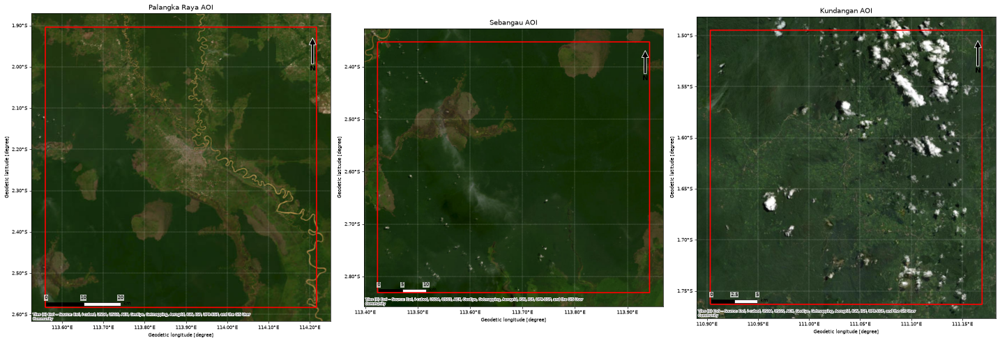

In [ ]:
fig, axes = plt.subplots(1, len(aois), figsize=(8 * len(aois), 8))

for ax, (name, aoi) in zip(np.atleast_1d(axes), aois.items()):
    aoi.boundary.plot(ax=ax, color="red", linewidth=2)

    xmin, ymin, xmax, ymax = aoi.total_bounds
    pad = 0.05 * max(xmax - xmin, ymax - ymin)
    ax.set_xlim(xmin - pad, xmax + pad)
    ax.set_ylim(ymin - pad, ymax + pad)
    cx.add_basemap(ax, crs=aoi.crs, source=cx.providers.Esri.WorldImagery, attribution_size=6)

    decorate(ax, f"{name.replace('_', ' ').title()} AOI")

plt.tight_layout()
plt.show()

## 3. Sentinel-1 composites as RGB

R = VV, G = VH, B = (VV - VH) / (VV + VH). Each channel uses one display range for all plots, the 2nd to 98th percentile of the valid pixels of all composites pooled, so colors are comparable between AOIs and dates.

In [ ]:
def load_s1(path):
    with rasterio.open(path) as src:
        data = src.read().astype("float32")
        names = [name.lower() for name in src.descriptions]
        bounds = src.bounds
        nodata = src.nodata or 0

    vv = data[names.index("vv")]
    vh = data[names.index("vh")]
    valid = (vv != nodata) & (vh != nodata)
    ratio = np.where(valid, (vv - vh) / np.where(valid, vv + vh, 1), 0)

    extent = (bounds.left, bounds.right, bounds.bottom, bounds.top)
    return np.stack([vv, vh, ratio]), valid, extent


def shared_ranges(images, low=2, high=98):
    # One display range per channel, from the valid pixels of all images together
    ranges = [
        np.percentile(np.concatenate([bands[i][valid] for bands, valid, _ in images.values()]), [low, high])
        for i in range(3)
    ]
    for channel, (lo, hi) in zip(["VV", "VH", "(VV-VH)/(VV+VH)"], ranges):
        print(f"{channel}: {lo:.3f} to {hi:.3f}")
    return ranges


def to_rgba(bands, valid, ranges):
    rgb = np.dstack([np.clip((band - lo) / (hi - lo), 0, 1) for band, (lo, hi) in zip(bands, ranges)])
    return np.dstack([rgb, valid.astype("float32")])


def plot_s1(images, ranges, title):
    fig, axes = plt.subplots(
        len(aois), len(S1_DATES), figsize=(8 * len(S1_DATES), 8 * len(aois)), squeeze=False
    )

    for row, (name, aoi) in zip(axes, aois.items()):
        for ax, date in zip(row, S1_DATES):
            bands, valid, extent = images[(name, date)]
            ax.imshow(to_rgba(bands, valid, ranges), extent=extent, interpolation="nearest")
            aoi.boundary.plot(ax=ax, color="yellow", linewidth=1.5)
            ax.set_xlim(extent[0], extent[1])
            ax.set_ylim(extent[2], extent[3])
            decorate(ax, f"{name.replace('_', ' ').title()} {title} {date}\n(R: VV, G: VH, B: (VV-VH)/(VV+VH))")

    plt.tight_layout()
    plt.show()


s1 = {
    (name, date): load_s1(f"{S1_PREFIX}/{name}_{date}.tif")
    for name in aois
    for date in S1_DATES
}
s1_ranges = shared_ranges(s1)

VV: 798.000 to 3388.000
VH: 169.000 to 807.000
(VV-VH)/(VV+VH): 0.458 to 0.725


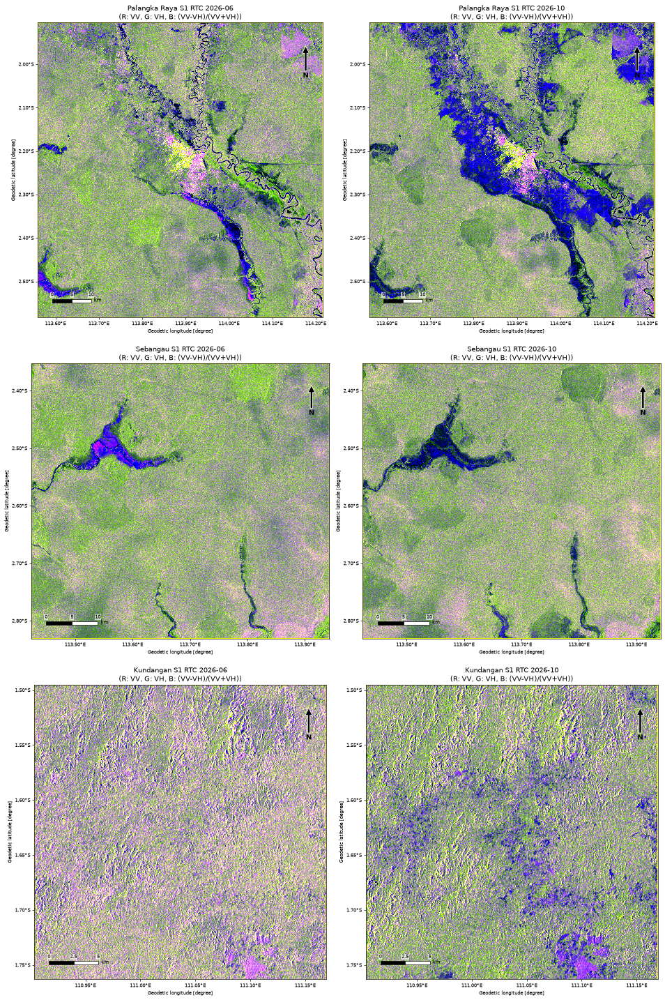

In [ ]:
plot_s1(s1, s1_ranges, "S1 RTC")

## 4. Surface water

OPERA DSWx-S1 water classification (`WTR`). Open water (1) and inundated vegetation (3) count as water. HAND masked (250, terrain too high above drainage for water) and layover/shadow (251, no reliable radar signal) are not water detections, so they are kept as non water.

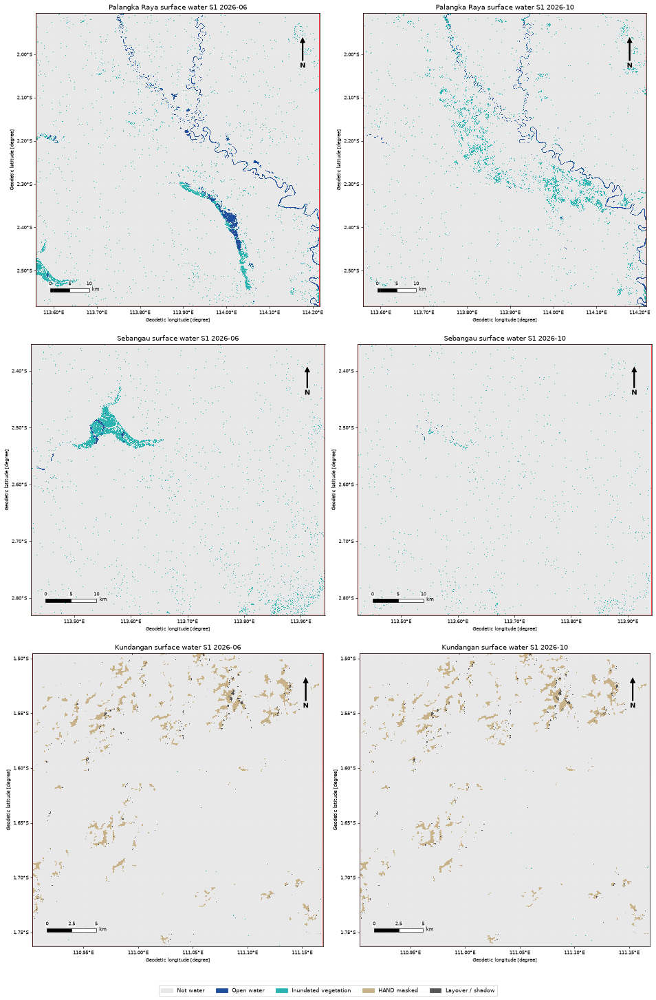

In [ ]:
WATER_CLASSES = {
    0: ("Not water", "#e8e8e8"),
    1: ("Open water", "#1f4e9c"),
    3: ("Inundated vegetation", "#2bb3b1"),
    250: ("HAND masked", "#c8b28a"),
    251: ("Layover / shadow", "#555555"),
}
WATER_VALUES = [1, 3]

water_cmap = ListedColormap([color for _, color in WATER_CLASSES.values()])
# Bin edges between the class values, so each value gets its own color
water_values = list(WATER_CLASSES)
water_norm = BoundaryNorm(
    [water_values[0] - 0.5]
    + [(a + b) / 2 for a, b in zip(water_values, water_values[1:])]
    + [water_values[-1] + 0.5],
    water_cmap.N,
)


def load_water(path):
    with rasterio.open(path) as src:
        wtr = src.read(1)
        nodata = src.nodata
        bounds = src.bounds
    extent = (bounds.left, bounds.right, bounds.bottom, bounds.top)
    return np.ma.masked_equal(wtr, nodata), extent


water = {
    (name, date): load_water(f"{WATER_PREFIX}/{name}_{date}.tif")
    for name in aois
    for date in S1_DATES
}

fig, axes = plt.subplots(
    len(aois), len(S1_DATES), figsize=(8 * len(S1_DATES), 8 * len(aois)), squeeze=False
)

for row, (name, aoi) in zip(axes, aois.items()):
    for ax, date in zip(row, S1_DATES):
        wtr, extent = water[(name, date)]
        ax.imshow(wtr, extent=extent, cmap=water_cmap, norm=water_norm, interpolation="nearest")
        aoi.boundary.plot(ax=ax, color="red", linewidth=1.5)
        ax.set_xlim(extent[0], extent[1])
        ax.set_ylim(extent[2], extent[3])
        decorate(ax, f"{name.replace('_', ' ').title()} surface water S1 {date}")

fig.legend(
    handles=[Patch(color=color, label=label) for label, color in WATER_CLASSES.values()],
    loc="lower center",
    ncol=len(WATER_CLASSES),
    bbox_to_anchor=(0.5, -0.01),
)
plt.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()

## 5. Sentinel-1 composites with water masked out

Water pixels (open water and inundated vegetation) of the same AOI and month are removed from the S1 composite. The display ranges are recomputed from the remaining non water pixels, shared by all plots.

palangka_raya 2026-06: 2.8% of valid S1 pixels masked as water
palangka_raya 2026-10: 2.8% of valid S1 pixels masked as water
sebangau 2026-06: 2.0% of valid S1 pixels masked as water
sebangau 2026-10: 0.6% of valid S1 pixels masked as water
kundangan 2026-06: 0.0% of valid S1 pixels masked as water
kundangan 2026-10: 0.0% of valid S1 pixels masked as water


VV: 903.000 to 3379.000
VH: 214.000 to 808.000
(VV-VH)/(VV+VH): 0.461 to 0.713


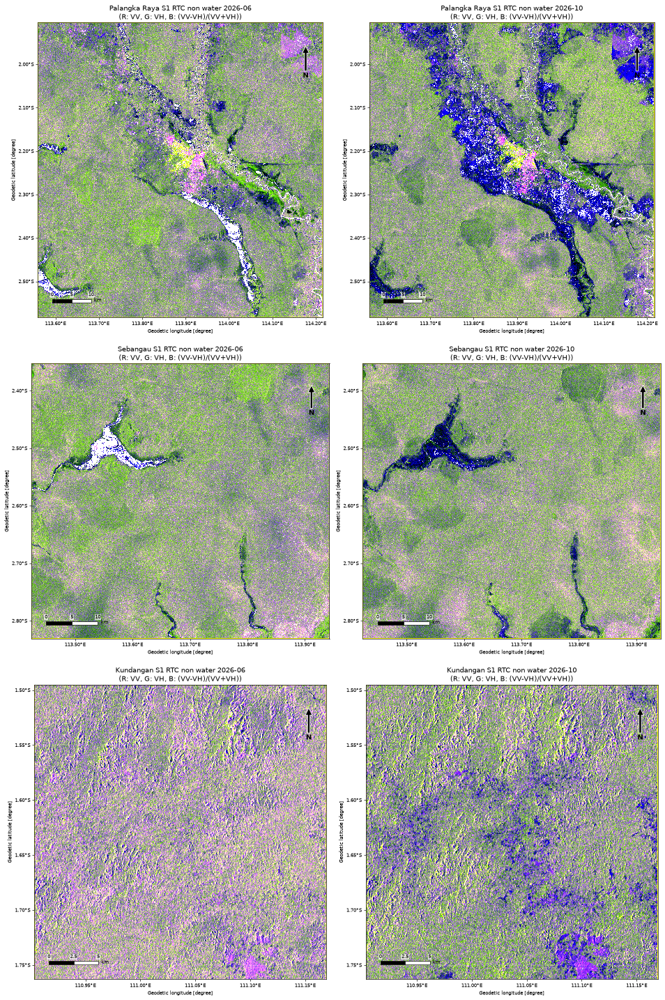

In [ ]:
s1_land = {}
for key, (bands, valid, extent) in s1.items():
    wtr, water_extent = water[key]
    # Same grid is needed to mask pixel by pixel
    assert wtr.shape == valid.shape and np.allclose(water_extent, extent), f"Grid mismatch {key}"
    is_water = np.isin(wtr.filled(0), WATER_VALUES)
    s1_land[key] = (bands, valid & ~is_water, extent)
    print(f"{key[0]} {key[1]}: {is_water[valid].mean():.1%} of valid S1 pixels masked as water")

s1_land_ranges = shared_ranges(s1_land)
plot_s1(s1_land, s1_land_ranges, "S1 RTC non water")